In [ ]:
from ppadb.client import Client

import numpy as np
import cv2

from PIL import Image, ImageFilter

adb = Client(host="127.0.0.1", port=5037)

devices = adb.devices()

if len(devices) == 0:
    print("No devices")
    
device = devices[0]

device.shell('input touchscreen swipe 500 500 500 500 2000')


''

: 

In [ ]:
# image = device.screencap()

# with open('screen.png', 'wb') as f:
#     f.write(image)

In [71]:


# image = cv2.imread("screen.png")
# points = []  # Store manually selected points

# # Function to select points
# def select_point(event, x, y, flags, param):
#     if event == cv2.EVENT_LBUTTONDOWN:  # Left click to select a point
#         points.append((x, y))
#         print(f"Point selected: {x}, {y}")
        
#         # Draw a red dot where the user clicked
#         cv2.circle(image, (x, y), 5, (0, 0, 255), -1)
#         cv2.imshow("Select Points", image)

# # Set up OpenCV window without resizing the image
# cv2.namedWindow("Select Points", cv2.WINDOW_NORMAL)  # Keeps image size intact
# cv2.resizeWindow("Select Points", 800, 600)  # Controls display window size only

# cv2.setMouseCallback("Select Points", select_point)

# # Show the image
# cv2.imshow("Select Points", image)
# cv2.waitKey(0)  # Wait for user input
# cv2.destroyAllWindows()

# # Print the manually selected points
# print("Selected Points:", points)






In [72]:
# image = cv2.imread("screen.png")

# # Manually selected points representing cell centers
# cell_points = [
#     (142, 665), (213, 629), (351, 629), (471, 629), (586, 629), (706, 629), (831, 634), (937, 634),
#     (133, 763), (235, 763), (337, 763), (484, 763), (604, 763), (724, 763), (831, 763), (960, 771),
#     (124, 882), (257, 887), (360, 869), (475, 882), (604, 887), (715, 887), (835, 882), (960, 882),
#     (137, 998), (244, 1007), (377, 1007), (480, 993), (586, 993), (706, 998), (840, 998), (960, 998),
#     (142, 1109), (235, 1109), (337, 1109), (466, 1109), (582, 1109), (706, 1113), (822, 1113), (951, 1113),
#     (124, 1237), (248, 1237), (337, 1237), (457, 1237), (600, 1237), (720, 1237), (831, 1237), (977, 1233),
#     (111, 1348), (257, 1353), (373, 1353), (471, 1353), (604, 1353), (720, 1353), (840, 1353), (955, 1353),
#     (133, 1486), (231, 1481), (337, 1481), (466, 1477), (577, 1477), (728, 1468), (835, 1463), (964, 1468)
# ]

# # **Step 1: Extract Color Information from Each Cell**
# cell_data = []
# for i, (x, y) in enumerate(cell_points):
#     color = image[y, x]  # Get the pixel color at (x, y)
#     cell_data.append(color)
#     print(f"Cell {i}: Color {color}")

#     # Draw a small circle at each detected cell
#     cv2.circle(image, (x, y), 5, (0, 0, 255), -1)  # Red dots on cells

# # **Step 2: Display the Grid with Proper Window Size**
# cv2.namedWindow("Detected Cells", cv2.WINDOW_NORMAL)  # Allow resizing
# cv2.resizeWindow("Detected Cells", 800, 600)  # Keep the display smaller

# cv2.imshow("Detected Cells", image)
# cv2.waitKey(0)
# cv2.destroyAllWindows()

In [73]:
# import cv2
# import numpy as np
# from collections import Counter

# # Load the full-size image
# image = cv2.imread("screen.png")

# # Manually selected points representing cell centers
# cell_points = [
#     (142, 665), (213, 629), (351, 629), (471, 629), (586, 629), (706, 629), (831, 634), (937, 634),
#     (133, 763), (235, 763), (337, 763), (484, 763), (604, 763), (724, 763), (831, 763), (960, 771),
#     (124, 882), (257, 887), (360, 869), (475, 882), (604, 887), (715, 887), (835, 882), (960, 882),
#     (137, 998), (244, 1007), (377, 1007), (480, 993), (586, 993), (706, 998), (840, 998), (960, 998),
#     (142, 1109), (235, 1109), (337, 1109), (466, 1109), (582, 1109), (706, 1113), (822, 1113), (951, 1113),
#     (124, 1237), (248, 1237), (337, 1237), (457, 1237), (600, 1237), (720, 1237), (831, 1237), (977, 1233),
#     (111, 1348), (257, 1353), (373, 1353), (471, 1353), (604, 1353), (720, 1353), (840, 1353), (955, 1353),
#     (133, 1486), (231, 1481), (337, 1481), (466, 1477), (577, 1477), (728, 1468), (835, 1463), (964, 1468)
# ]

# # Define the reference "empty cell" color
# empty_color = np.array([66, 36, 25])  # Target color for empty cells
# tolerance = 20  # Allow slight variations in color

# # Store empty/occupied status
# cell_status = []

# # **Step 1: Sample Multiple Pixels Per Cell**
# for i, (x, y) in enumerate(cell_points):
#     # Define sample points (cross pattern around the center)
#     sample_offsets = [(-3, 0), (3, 0), (0, -3), (0, 3), (0, 0)]
#     sampled_colors = []

#     for dx, dy in sample_offsets:
#         sx, sy = min(image.shape[1] - 1, max(0, x + dx)), min(image.shape[0] - 1, max(0, y + dy))
#         sampled_colors.append(tuple(image[sy, sx]))  # Convert to tuple for counting

#     # Find the most common color among sampled points
#     most_common_color, _ = Counter(sampled_colors).most_common(1)[0]
#     most_common_color = np.array(most_common_color)

#     # Check if this matches the empty color (with tolerance)
#     is_empty = np.all(np.abs(most_common_color - empty_color) < tolerance)
#     cell_status.append(is_empty)

#     # Print status
#     status = "EMPTY" if is_empty else "OCCUPIED"
#     print(f"Cell {i}: Most Common Color {most_common_color} -> {status}")

#     # **Step 2: Draw Markers to Visualize Results**
#     marker_color = (0, 255, 0) if is_empty else (0, 0, 255)  # Green for empty, Red for occupied
#     cv2.circle(image, (x, y), 5, marker_color, -1)  # Draw marker

# # **Step 3: Display the Result with a Proper Window Size**
# cv2.namedWindow("Grid Status", cv2.WINDOW_NORMAL)  # Keep screen size intact
# cv2.resizeWindow("Grid Status", 800, 600)  # Keep window small but full image

# # cv2.imshow("Grid Status", image)
# # cv2.waitKey(0)
# # cv2.destroyAllWindows()

# import matplotlib.pyplot as plt

# # Convert BGR to RGB for correct display in Matplotlib
# image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# # Display inside the notebook
# plt.figure(figsize=(10, 6))
# plt.imshow(image_rgb)
# plt.axis("off")  # Hide axis labels
# plt.title("Grid Status")
# plt.show()

# GRID_COLS = 10
# grid_matrix = np.array(cell_status, dtype=int).reshape(-1, GRID_COLS)

# # Print the grid state for debugging
# print("Current Grid State:")
# print(grid_matrix)


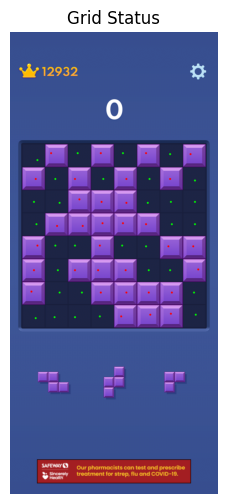

Current Grid State:
[[1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 1 0 0 0 1 1 1]
 [1 0 0 0 0 0 1 1]
 [0 1 1 0 1 1 0 0]
 [0 1 0 0 0 1 1 0]
 [0 1 1 0 0 0 0 1]
 [1 1 1 1 0 0 0 1]]


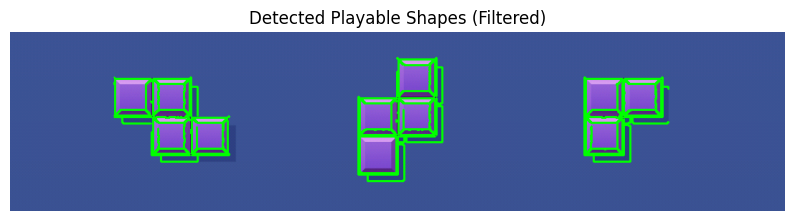

In [74]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("screen.png")

cell_points = [
    (142, 665), (213, 629), (351, 629), (471, 629), (586, 629), (706, 629), (831, 634), (937, 634),
    (133, 763), (235, 763), (337, 763), (484, 763), (604, 763), (724, 763), (831, 763), (960, 771),
    (124, 882), (257, 887), (360, 869), (475, 882), (604, 887), (715, 887), (835, 882), (960, 882),
    (137, 998), (244, 1007), (377, 1007), (480, 993), (586, 993), (706, 998), (840, 998), (960, 998),
    (142, 1109), (235, 1109), (337, 1109), (466, 1109), (582, 1109), (706, 1113), (822, 1113), (951, 1113),
    (124, 1237), (248, 1237), (337, 1237), (457, 1237), (600, 1237), (720, 1237), (831, 1237), (977, 1233),
    (111, 1348), (257, 1353), (373, 1353), (471, 1353), (604, 1353), (720, 1353), (840, 1353), (955, 1353),
    (133, 1486), (231, 1481), (337, 1481), (466, 1477), (577, 1477), (728, 1468), (835, 1463), (964, 1468)
]

empty_color = np.array([66, 36, 25]) 
tolerance = 15 

cell_status = []

for i, (x, y) in enumerate(cell_points):
    sample_offsets = [(-3, 0), (3, 0), (0, -3), (0, 3), (0, 0)]
    sampled_colors = []

    for dx, dy in sample_offsets:
        sx, sy = min(image.shape[1] - 1, max(0, x + dx)), min(image.shape[0] - 1, max(0, y + dy))
        sampled_colors.append(image[sy, sx]) 

    sampled_colors = np.array(sampled_colors)

    median_color = np.median(sampled_colors, axis=0).astype(int)

    is_empty = np.all(np.abs(median_color - empty_color) < tolerance)
    cell_status.append(is_empty)

    status = "EMPTY" if is_empty else "OCCUPIED"
    # print(f"Cell {i}: Median Color {median_color} -> {status}")

    marker_color = (0, 255, 0) if is_empty else (0, 0, 255) 
    cv2.circle(image, (x, y), 5, marker_color, -1) 

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(image_rgb)
plt.axis("off") 
plt.title("Grid Status")
plt.show()

GRID_COLS = 8 
grid_matrix = np.array(cell_status, dtype=int).reshape(-1, GRID_COLS)

print("Current Grid State:")
print(grid_matrix)


shapes_region = image[1700:1950, :]  # Crop the lower portion (Y-range)

shapes_gray = cv2.cvtColor(shapes_region, cv2.COLOR_BGR2GRAY)

# Apply edge detection
edges = cv2.Canny(shapes_gray, 50, 150)

# Find contours with hierarchy
contours, hierarchy = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Create a blank mask to draw only the outermost contours
shape_mask = np.zeros_like(shapes_gray)

# **Step 1: Filter Contours to Keep Only Outermost Shapes**
outer_contours = []

for i, cnt in enumerate(contours):
    if hierarchy[0][i][3] == -1:  # Keep only outermost contours (no parent)
        outer_contours.append(cnt)

# Draw only the outermost contours on a copy of the image
shapes_detected = shapes_region.copy()
cv2.drawContours(shapes_detected, outer_contours, -1, (0, 255, 0), 2)  # Green outlines

# Convert for display in notebook
shapes_detected_rgb = cv2.cvtColor(shapes_detected, cv2.COLOR_BGR2RGB)

# Show the detected shapes with outer contours only
plt.figure(figsize=(10, 3))
plt.imshow(shapes_detected_rgb)
plt.axis("off")
plt.title("Detected Playable Shapes (Filtered)")
plt.show()


shape_images = []  # Store each detected shape


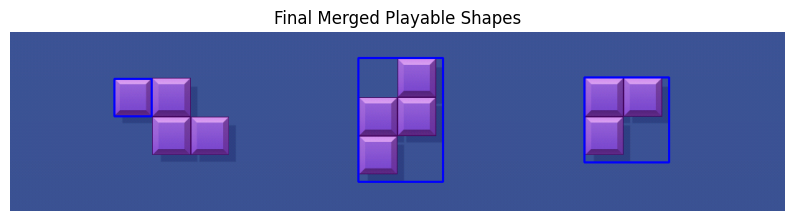

In [75]:
# **Filter contours by area to remove tiny fragments**
filtered_contours = [cnt for cnt in contours if cv2.contourArea(cnt) > 500]  # Adjust area threshold

# **Merge overlapping bounding boxes to reduce separate detections**
def merge_bounding_boxes(contours):
    bounding_boxes = [cv2.boundingRect(cnt) for cnt in contours]
    merged_boxes = []

    while bounding_boxes:
        x, y, w, h = bounding_boxes.pop(0)  # Take the first box
        merged = False

        for i, (mx, my, mw, mh) in enumerate(merged_boxes):
            # Check if this box overlaps significantly with an existing box
            if (x < mx + mw + 20 and x + w > mx - 20) and (y < my + mh + 20 and y + h > my - 20):
                # Merge boxes by expanding existing one
                merged_boxes[i] = (
                    min(x, mx), min(y, my), max(x + w, mx + mw) - min(x, mx), max(y + h, my + mh) - min(y, my)
                )
                merged = True
                break

        if not merged:
            merged_boxes.append((x, y, w, h))

    return merged_boxes

# Merge nearby bounding boxes
merged_boxes = merge_bounding_boxes(filtered_contours)

# Draw final merged bounding boxes
shapes_final = shapes_region.copy()
for (x, y, w, h) in merged_boxes:
    cv2.rectangle(shapes_final, (x, y), (x + w, y + h), (255, 0, 0), 2)  # Blue bounding boxes

# Convert for display in notebook
shapes_final_rgb = cv2.cvtColor(shapes_final, cv2.COLOR_BGR2RGB)

# Show the final detected shapes
plt.figure(figsize=(10, 3))
plt.imshow(shapes_final_rgb)
plt.axis("off")
plt.title("Final Merged Playable Shapes")
plt.show()


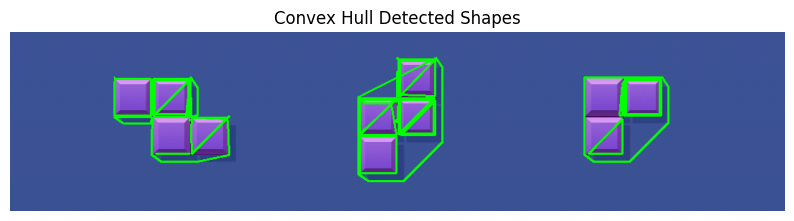

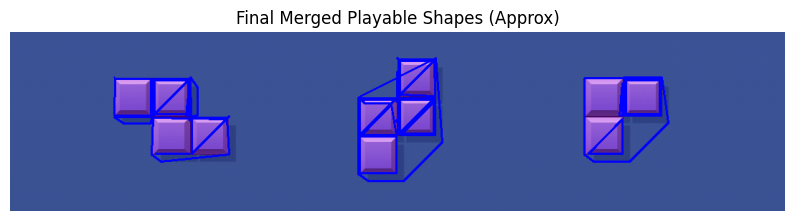

In [77]:
convex_hulls = [cv2.convexHull(cnt) for cnt in contours]

# Draw convex hulls on the image
shapes_detected = shapes_region.copy()
cv2.drawContours(shapes_detected, convex_hulls, -1, (0, 255, 0), 2)  # Green outlines

# Convert for display in notebook
shapes_detected_rgb = cv2.cvtColor(shapes_detected, cv2.COLOR_BGR2RGB)

# Show detected shapes with convex hulls
plt.figure(figsize=(10, 3))
plt.imshow(shapes_detected_rgb)
plt.axis("off")
plt.title("Convex Hull Detected Shapes")
plt.show()

# **Step 2: Approximate Shape Boundaries for Better Detection**
approx_shapes = []

for hull in convex_hulls:
    epsilon = 0.02 * cv2.arcLength(hull, True)  # Reduce complexity
    approx = cv2.approxPolyDP(hull, epsilon, True)  # Simplify shape
    approx_shapes.append(approx)

# Draw approximated shapes on the image
shapes_final = shapes_region.copy()
cv2.drawContours(shapes_final, approx_shapes, -1, (255, 0, 0), 2)  # Blue outlines

# Convert for display in notebook
shapes_final_rgb = cv2.cvtColor(shapes_final, cv2.COLOR_BGR2RGB)

# Show final approximated shapes
plt.figure(figsize=(10, 3))
plt.imshow(shapes_final_rgb)
plt.axis("off")
plt.title("Final Merged Playable Shapes (Approx)")
plt.show()